In [3]:
import os, glob, json, shutil
found = [r for r, d, f in os.walk('/kaggle/input', followlinks=True) if 'pyproject.toml' in f]
print('code found at:', found)
shutil.copytree(found[0], '/kaggle/working/mhs-project', dirs_exist_ok=True)
os.chdir('/kaggle/working/mhs-project')
!pip install -q -e ".[acquire]"
!mhs event-eval --help > /dev/null && echo "v12 loaded" || echo "OLD VERSION - update the code dataset"
!grep -q cop30_aws_urls mhs/acquire.py && echo "DEM fix present" || echo "DEM FIX MISSING - update the code dataset"
if not os.path.exists('data/chamoli/t1.tif'):
    !mhs acquire configs/chamoli.yaml --out data/chamoli > acquire.log
!ls data/chamoli
poly = glob.glob('/kaggle/input/**/labels.geojson', recursive=True)[0]
feats = json.load(open(poly))['features']
print('labels file:', poly, '| polygons:', len(feats))
!mhs rasterize-labels configs/chamoli.yaml --polygons {poly} --out data/chamoli/labels.tif

code found at: ['/kaggle/input/datasets/ilikesomeone/mountain-hazard-screening-12/mountain-hazard-screening']
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for mhs (pyproject.toml) ... done
v12 loaded
DEM fix present
acquisition.json  t1_scl.tif  t2_scl.tif  t3_scl.tif
dem.tif		  t1.tif      t2.tif	  t3.tif
labels file: /kaggle/input/datasets/ilikesomeone/chamoli-labels/labels.geojson | polygons: 63
{
  "out": "data/chamoli/labels.tif",
  "polygons": 63,
  "pixels_per_class": {
    "t1": {
      "background": 9955,
      "water": 0,
      "snow_ice": 20450,
      "rock": 4465,
      "soil": 18962,
      "debris": 0
    },
    "t2": {
      "background": 10604,
      "water": 0,
      "snow_ice": 20487,
      "rock": 10980,
      "soil": 30332,
      "debris": 2077
    }
  }
}
labelled pixels per split strip

In [4]:
os.chdir('/kaggle/working/mhs-project')
!mhs benchmark configs/chamoli.yaml --out models/bench --seeds 0
!ls -lh models/bench/seed_0

--- seed 0 ---
seed 0: best epoch 17, test macro F1 0.747

U-Net (1 seeds) vs rule baseline, held-out test strip
class           support   U-Net F1 mean ± sd       min-max  baseline F1
background         1225       1.000 ± 0.000  1.000-1.000        0.713
snow_ice          11322       1.000 ± 0.000  1.000-1.000        1.000
rock               1535       0.432 ± 0.000  0.432-0.432        0.354
soil               5285       0.555 ± 0.000  0.555-0.555        0.009
macro_f1                      0.747 ± 0.000  0.747-0.747        0.519
overall_accuracy                0.815 ± 0.000  0.815-0.815        0.695
total 30M
-rw-r--r-- 1 root root 5.9K Nov  1 07:26 training_record.json
-rw-r--r-- 1 root root  30M Nov  1 07:25 unet.pt


In [5]:
os.chdir('/kaggle/working/mhs-project')
!mhs benchmark configs/chamoli.yaml --out models/bench_aws --seeds 0 1 2
!nvidia-smi --query-gpu=name --format=csv
!cp models/bench_aws/benchmark.json /kaggle/working/benchmark_aws.json

--- seed 0 ---
seed 0: best epoch 25, test macro F1 0.617
--- seed 1 ---
seed 1: best epoch 6, test macro F1 0.730
--- seed 2 ---
seed 2: best epoch 8, test macro F1 0.581

U-Net (3 seeds) vs rule baseline, held-out test strip
class           support   U-Net F1 mean ± sd       min-max  baseline F1
background         1225       0.984 ± 0.016  0.967-0.996        0.713
snow_ice          11322       1.000 ± 0.000  1.000-1.000        1.000
rock               1535       0.278 ± 0.094  0.170-0.343        0.354
soil               5285       0.309 ± 0.393  0.015-0.755        0.009
macro_f1                      0.643 ± 0.078  0.581-0.730        0.519
overall_accuracy                0.766 ± 0.087  0.704-0.866        0.695
name
Tesla T4
Tesla T4


In [6]:
!mhs osm-assets configs/chamoli.yaml --out data/chamoli/assets.geojson

{
  "out": "data/chamoli/assets.geojson",
  "features": 45,
  "by_type": {
    "settlement": 37,
    "bridge": 8
  },
  "osm_data_date": "2026-11-01T07:41:18Z"
}


In [7]:
os.chdir('/kaggle/working/mhs-project')
for s in (0, 1, 2):
    print(f'=== U-Net seed {s} ===')
    !mhs run configs/chamoli.yaml --model models/bench_aws/seed_{s}/unet.pt --out runs/chamoli_unet_s{s} | tail -4
print('=== rule baseline ===')
!mhs run configs/chamoli.yaml --out runs/chamoli_rules | tail -4

=== U-Net seed 0 ===
     snow_ice -> soil           1.01 km2
   background -> rock           0.82 km2
   usable on both dates: 317.8 km2 (63% of scene)
done: 371 zones; report at runs/chamoli_unet_s0/report.md
=== U-Net seed 1 ===
     snow_ice -> rock           0.28 km2
     snow_ice -> background     0.24 km2
   usable on both dates: 317.8 km2 (63% of scene)
done: 126 zones; report at runs/chamoli_unet_s1/report.md
=== U-Net seed 2 ===
         rock -> debris         0.45 km2
   background -> debris         0.39 km2
   usable on both dates: 317.8 km2 (63% of scene)
done: 131 zones; report at runs/chamoli_unet_s2/report.md
=== rule baseline ===
   background -> rock           2.23 km2
     snow_ice -> soil           2.21 km2
   usable on both dates: 317.8 km2 (63% of scene)
done: 434 zones; report at runs/chamoli_rules/report.md


routing from the documented source ...
# Event evaluation: Chamoli rock-ice avalanche, 7 Feb 2021
run: `runs/chamoli_unet_s0` (unet), 371 zones

## Documented source (within 1 km)
elevation 5288.8 m, slope 39.2 deg, aspect 43.7 deg; usable on both dates 86%; shadow t1 73%, t2 47%, both 47%
classes t1 {'background': 0.0, 'snow_ice': 0.697, 'rock': 0.001, 'soil': 0.264, 'debris': 0.037}; t2 {'snow_ice': 0.709, 'rock': 0.004, 'soil': 0.283, 'debris': 0.004}
changed pixels before zone rules 112; in zones 0

## Ranking of the documented source (energy term is an index (rho*g*area*drop, J per metre of thickness): no thickness scenario declared)

### zones within 500 m: 0 (random expectation for best rank: None)
no zone at the documented source

### zones within 1000 m: 0 (random expectation for best rank: None)
no zone at the documented source

### zones within 2000 m: 1 (random expectation for best rank: 186.0)
| ranking | best rank | percentile | top 5 | top 10 | top 25 |
|---|---|---|---|

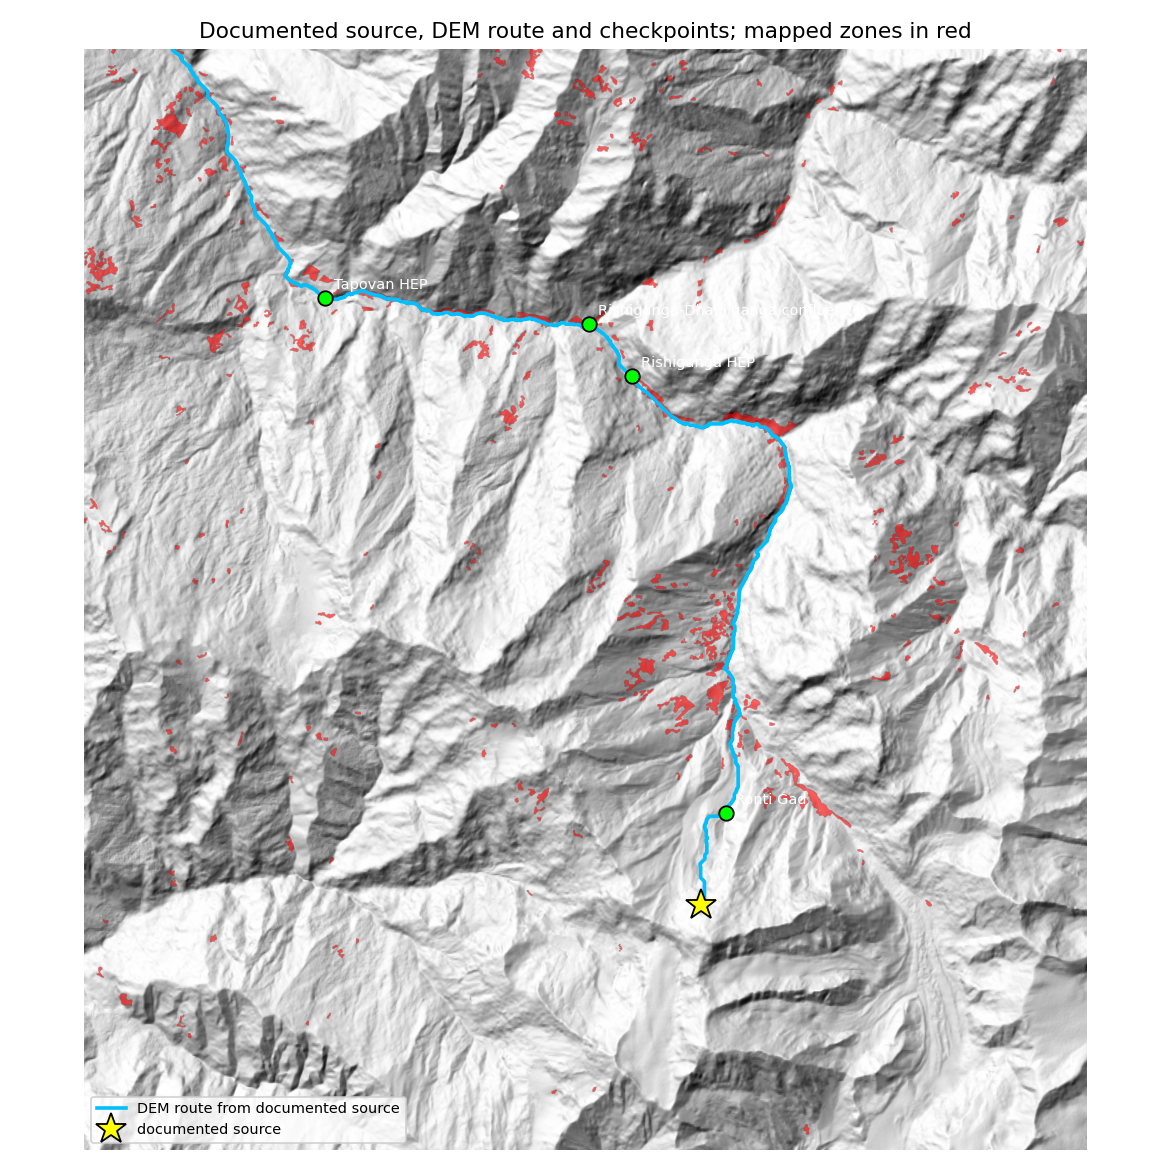

In [9]:
for s in (0, 1, 2):
    !mhs event-eval configs/chamoli.yaml runs/chamoli_unet_s{s} --out runs/event_eval_unet_s{s}
!mhs event-eval configs/chamoli.yaml runs/chamoli_rules --out runs/event_eval_rules
from IPython.display import Image, display
display(Image('runs/event_eval_unet_s0/event_route.png'))

In [15]:
!cd runs && zip -qr event_eval.zip event_eval_* chamoli_*/report.md && ls -lh event_eval.zip
!cp runs/event_eval.zip /kaggle/working/
from IPython.display import FileLink
os.chdir('/kaggle/working'); FileLink('event_eval.zip')

/bin/bash: line 1: cd: runs: No such file or directory
cp: cannot stat 'runs/event_eval.zip': No such file or directory


/kaggle/working/event_eval.zip